<a href="https://colab.research.google.com/github/clobos/ECO5056_2026/blob/main/semana4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Formulário e Interpretação de Métricas de Classificação Binária

Este guia descreve matematicamente e conceitualmente as métricas de desempenho empregadas no desenvolvimento, validação e teste dos modelos avaliados neste notebook.

---

## 1. Matriz de Confusão e suas Variáveis de Base
A **Matriz de Confusão** (`confusion_matrix`) é uma tabela quadrada de tamanho $2 \times 2$ que mapeia as classes reais contra as classes previstas pelo classificador:

* **Verdadeiro Positivo ($VP$)**: O caso é real positivo ($1$) e foi previsto como positivo ($1$).
* **Verdadeiro Negativo ($VN$)**: O caso é real negativo ($0$) e foi previsto como negativo ($0$).
* **Falso Positivo ($FP$)** (Erro Tipo I): O caso é real negativo ($0$), mas o modelo previu incorretamente como positivo ($1$).
* **Falso Negativo ($FN$)** (Erro Tipo II): O caso é real positivo ($1$), mas o modelo previu incorretamente como negativo ($0$).

---

## 2. Métricas de Classificação Operacionais (Baseadas em Limiar)

### Precisão (`precision_score`)
Mede a taxa de acerto do modelo quando ele assume que uma instância pertence à classe positiva.
$$\text{Precisão} = \frac{VP}{VP + FP}$$
* **Interpretação prática**: De todos os pacientes/amostras que o modelo sinalizou com alerta (positivo), quantos realmente tinham a condição? Uma precisão alta evita falsos alarmes e inspeções desnecessárias.

### Sensibilidade / Rechamada / Revocação (`recall_score`)
Mede a capacidade do classificador de identificar e capturar as instâncias reais da classe positiva.
$$\text{Sensibilidade} = \frac{VP}{VP + FN}$$
* **Interpretação prática**: De todos os casos verdadeiramente positivos que existem no conjunto, que proporção o modelo detectou? Essencial em áreas críticas como medicina e detecção de pragas, onde deixar passar um caso positivo (falso negativo) é perigoso.

### Especificidade
Mede a taxa de acerto do modelo na classe negativa real.
$$\text{Especificidade} = \frac{VN}{VN + FP}$$
* **Interpretação prática**: De todas as amostras saudáveis, qual proporção foi identificada corretamente como livre da condição?

### Medida F1 (`f1_score`)
A média harmônica entre a precisão e a sensibilidade.
$$F_1 = 2 \times \frac{\text{Precisão} \times \text{Sensibilidade}}{\text{Precisão} + \text{Sensibilidade}} = \frac{2VP}{2VP + FP + FN}$$
* **Interpretação prática**: Oferece uma única métrica robusta de equilíbrio. É preferível à acurácia geral quando as classes são desbalanceadas.

### Medida F-Beta (`fbeta_score`)
Uma generalização da medida F1 que introduz o coeficiente $\beta$ para ajustar o peso relativo dado à Sensibilidade frente à Precisão.
$$F_{\beta} = (1 + \beta^2) \times \frac{\text{Precisão} \times \text{Sensibilidade}}{(\beta^2 \times \text{Precisão}) + \text{Sensibilidade}}$$
* **Interpretação prática**:
  * Se $\beta = 2$ ($F_2$): A Sensibilidade recebe o dobro do peso da Precisão. Ideal quando falsos negativos são muito piores que falsos positivos.
  * Se $\beta = 0.5$ ($F_{0.5}$): A Precisão recebe maior relevância. Ideal quando o custo do falso alarme é muito alto.

### Acurácia Balanceada (`balanced_accuracy_score`)
A média simples entre a sensibilidade (taxa de acertos nos positivos) e a especificidade (taxa de acertos nos negativos).
$$\text{Acurácia Balanceada} = \frac{\text{Sensibilidade} + \text{Especificidade}}{2}$$
* **Interpretação prática**: Evita o 'paradoxo da acurácia' em dados desbalanceados. Se um classificador chutar apenas a classe majoritária (ex: 95% dos dados), a acurácia geral será de 95%, mas a acurácia balanceada cairá para 50%, refletindo o real desempenho nulo na classe minoritária.

---

## 3. Avaliação de Escores Probabilísticos (Independentes de Limiar)

### Curva ROC e Área sob a Curva ROC (`roc_curve`, `roc_auc_score`)
A curva ROC plota a Taxa de Verdadeiros Positivos (Sensibilidade, eixo Y) contra a Taxa de Falsos Positivos ($1 - \text{Especificidade}$, eixo X) computada em todas as partições possíveis de probabilidade.
* **Interpretação prática**: O $AUC\text{-}ROC$ varia de $0.5$ (modelo aleatório) a $1.0$ (modelo perfeito). Indica a probabilidade de que um exemplo positivo selecionado aleatoriamente receba uma probabilidade predita maior do que um exemplo negativo selecionado aleatoriamente.

### Curva de Precisão-Recall e Average Precision (`precision_recall_curve`, `average_precision_score`)
A curva PR mapeia a Precisão (eixo Y) contra a Sensibilidade (eixo X) em cada limiar de decisão.
* **Interpretação prática**: O $AP$ aproxima a área sob a curva PR. É a métrica mais indicada para avaliar problemas com classes altamente desbalanceadas (ex: eventos raros), pois ignora os Verdadeiros Negativos que superam em muito a classe positiva, concentrando-se na detecção correta sem inflacionar artificialmente o desempenho.

### Erro Quadrático Brier (`brier_score_loss`)
Avalia a qualidade e a calibração de probabilidade calculando o erro médio quadrático entre a probabilidade estimada $\hat{p}_i$ e o desfecho binário real $y_i \in \{0, 1\}$.
$$\text{Brier} = \frac{1}{N} \sum_{i=1}^{N} (\hat{p}_i - y_i)^2$$
* **Interpretação prática**: Varia de $0$ a $1$. Quanto mais próximo de zero, melhor calibradas estão as probabilidades do modelo (um modelo que prevê probabilidade de 0.90 para casos que de fato ocorrem em 90% das vezes terá um Brier Score excelente).

---

## 4. Métricas de Impureza de Divisão para Árvores de Decisão

As divisões nos nós de árvores de decisão CART são baseadas na minimização da impureza do nó resultante. As duas funções de critério mais empregadas são:

### A. Impureza de Gini

#### Caso Geral ($K$ Categorias)
Para um nó contendo registros pertencentes a $K$ classes diferentes, onde $p_i$ é a probabilidade estimada (frequência relativa) de um registro pertencer à classe $i$:
$$I_G(p) = 1 - \sum_{i=1}^{K} p_i^2$$

#### Caso Binário ($K = 2$)
Considerando as proporções das duas únicas classes como $p$ (classe positiva) e $(1 - p)$ (classe negativa):
$$I_G(p) = 1 - [p^2 + (1-p)^2] = 2p(1 - p)$$

### B. Entropia de Shannon

#### Caso Geral ($K$ Categorias)
Origina-se da teoria da informação para mensurar o nível de desordem ou incerteza contido em uma distribuição de dados:
$$H(p) = - \sum_{i=1}^{K} p_i \log_2(p_i)$$
*(Por convenção matemática, se $p_i = 0$, adota-se $0 \log_2(0) = 0$)*.

#### Caso Binário ($K = 2$)
Com probabilidade $p$ para a classe ativa e $(1 - p)$ para a classe negativa:
$$H(p) = - [p \log_2(p) + (1 - p) \log_2(1 - p)]$$

### Referências Bibliográficas Clássicas
1. **Breiman, L., Friedman, J., Stone, C. J., & Olshen, R. A. (1984)**. *Classification and Regression Trees*. Belmont, CA: Wadsworth International Group. (Referência seminal para o algoritmo CART e aplicação da Impureza de Gini).
2. **Shannon, C. E. (1948)**. *A Mathematical Theory of Communication*. Bell System Technical Journal, 27(3), 379-423. (Origem teórica da Entropia da Informação).
3. **Quinlan, J. R. (1986)**. *Induction of Decision Trees*. Machine Learning, 1(1), 81-106. (Introdução da entropia na geração de árvores de decisão via algoritmos ID3/C4.5).

---

## 5. Ferramentas de Relatório e Visualizações Utilizadas

* **`classification_report`**: Função utilitária que gera uma tabela resumindo as principais métricas calculadas em nível de classe individualizada, permitindo uma inspeção rápida do desempenho geral.
* **`ConfusionMatrixDisplay`**: Classe de plotagem do scikit-learn para renderizar visualmente os fluxos de acerto e erro em formato de mapa de calor.
* **`PrecisionRecallDisplay`**: Renderiza a curva PR e anota a pontuação de precisão média (AP).
* **`RocCurveDisplay`**: Renderiza a curva ROC e anota a área sob a curva (AUC).

# Teoria Geral e Fluxo de Modelagem de Machine Learning

Este notebook apresenta abordagens rigorosas para resolução de problemas de classificação binária (diagnóstico médico e ocorrência de doenças em plantas) aplicando boas práticas de Engenharia de Recursos e Aprendizado Supervisionado.

---

## 1. Vazamento de Dados (Data Leakage) e o Papel dos Pipelines

O vazamento de dados ocorre quando informações do conjunto de validação ou teste "vazam" para o processo de treinamento do algoritmo de aprendizado. Isso gera estimativas excessivamente otimistas e irreais do desempenho em produção.

* **Como o vazamento ocorre tradicionalmente?** Se você computar a média e o desvio padrão de todo o seu conjunto de dados para aplicar uma normalização (como o `StandardScaler`), ou imputar valores nulos com base na mediana geral de toda a base, informações das partições que deveriam ser ocultadas no treino já foram consumidas pelo preprocessador.
* **A Solução via Pipelines**: O uso de `Pipeline` (`sklearn` ou `imblearn`) encapsula as operações de preprocessamento e o estimador em uma única entidade. Ao executar uma validação cruzada com o Pipeline, o método `fit` do preprocessador é recalculado estritamente usando apenas as dobras de treino internas daquela rodada, garantindo o isolamento absoluto dos conjuntos de validação.

---

## 2. Tratamento de Dados Desbalanceados

Conjuntos de dados desbalanceados possuem uma classe que supera numericamente a outra em proporções extremas. Se não tratados, os modelos tendem a ignorar a classe minoritária (evento de interesse), pois focar na classe majoritária é o caminho mais rápido para reduzir o erro global.

### A. Penalização de Erros (class_weight="balanced")
Esta técnica altera a função de custo do modelo (como a entropia cruzada da regressão logística ou a impureza nas divisões de uma árvore).
* Cada amostra recebe um peso inversamente proporcional à frequência de sua respectiva classe no conjunto de treinamento:
  $$w_c = \frac{N_{\text{amostras}}}{C_{\text{classes}} \times N_c}$$
* Errar um exemplo da classe minoritária acarreta uma penalidade muito maior para o algoritmo, forçando-o a aprender as fronteiras que limitam essa classe.

### B. Geração de Sintéticos (SMOTE)
A técnica **SMOTE** (*Synthetic Minority Over-sampling Technique*) gera novos dados artificiais para a classe minoritária preenchendo o espaço geométrico entre exemplos existentes desta classe através de interpolação linear utilizando vizinhos próximos ($k$-NN).

---

## 3. Métodos baseados em Árvores de Decisão e Ensembles

### A. Árvores de Decisão (Decision Trees)
Algoritmos não-paramétricos que dividem recursivamente o espaço amostral em sub-regiões ortogonais homogêneas com base em critérios de pureza (Gini ou Entropia).
* **Vantagens**: Alta interpretabilidade física.
* **Desvantagens**: Alta variância. Pequenas oscilações no conjunto de treinamento mudam drasticamente a estrutura e as decisões de partição da árvore.

### B. Bagging (Bootstrap Aggregating)
Técnica que treina várias árvores de decisão independentes em paralelo utilizando subconjuntos gerados via amostragem com reposição (Bootstrap) da base de treino original.
* A predição final resulta da média (regressão) ou votação majoritária (classificação) de todas as árvores.
* **Efeito prático**: Reduz expressivamente a variância do modelo sem aumentar o viés.

### C. Random Forest (Florestas Aleatórias)
Uma extensão do Bagging projetada para quebrar a correlação entre as árvores geradas no processo de bootstrap.
* Durante a escolha da divisão de cada nó de cada árvore, o algoritmo seleciona apenas um subconjunto aleatório de variáveis (geralmente $\sqrt{P}$, onde $P$ é o total de preditores).
* **Efeito prático**: Produz árvores altamente descorrelacionadas entre si. Ao combinar os votos de estimadores independentes e distintos, a variância do modelo final é drasticamente menor do que a de árvores de decisão tradicionais.

---

## 4. Otimização de Hiperparâmetros (`GridSearchCV`)

Enquanto os parâmetros do modelo são aprendidos diretamente a partir dos dados durante a fase de treinamento, os **hiperparâmetros** devem ser definidos antes de iniciar o treino e controlam a arquitetura e complexidade do algoritmo (ex: profundidade máxima de uma árvore, número de estimadores).

O `GridSearchCV` realiza uma busca exaustiva (força bruta) através de uma grade especificada de valores de hiperparâmetros, avaliando cada combinação candidata por meio de validação cruzada estruturada (`StratifiedKFold`). O pipeline que obtiver o melhor escore médio (por exemplo, maximizando a métrica `PR-AUC`) é automaticamente reajustado com todo o conjunto de desenvolvimento original utilizando o parâmetro `refit=True`.

---

## 5. Seleção de Limiares Operacionais de Decisão

Classificadores estatísticos e de aprendizado de máquina não produzem classificações discretas diretamente, mas sim escores contínuos de probabilidade (ex: $0.78$ de chance de doença).

* Por padrão, o limiar de corte para classificar um caso como positivo é de $0.50$.
* Em problemas reais, o custo associado a um falso negativo (não detectar um tumor maligno) é muito superior ao custo de um falso positivo (pedir exames adicionais para confirmação).
* Para otimizar essa decisão de negócio ou de saúde, ajustamos o limiar varrendo as probabilidades geradas fora da dobra (Out-of-Fold) na validação cruzada, selecionando o ponto que maximiza uma função de utilidade (como a métrica $F_2$ ou $F_{\beta}$).


GUIA DE MÉTRICAS DE AVALIAÇÃO DE CLASSIFICAÇÃO BINÁRIA


 1. MATRIZ DE CONFUSÃO (confusion_matrix)
    Representação tabular dos acertos e erros do classificador:
    - Verdadeiro Positivo (VP): Casos positivos classificados corretamente.
    - Verdadeiro Negativo (VN): Casos negativos classificados corretamente.
    - Falso Positivo (FP): Casos negativos classificados incorretamente como positivos (Erro Tipo I).
    - Falso Negativo (FN): Casos positivos classificados incorretamente como negativos (Erro Tipo II).

 2. PRECISÃO / VALOR PREDITIVO POSITIVO (precision_score)
    Mede a exatidão das predições positivas.
    Fórmula: Precision = VP / (VP + FP)
    Interpretação: Das instâncias classificadas como positivas, qual proporção é realmente positiva.

 3. SENSIBILIDADE / RECALL / REVOCAÇÃO / TAXA DE VERDADEIROS POSITIVOS (recall_score)
    Mede a capacidade de identificar todas as instâncias positivas reais.
    Fórmula: Recall (Sensibilidade) = VP / (VP + FN)
    Interpretação: De todas as instâncias realmente positivas, quanto o modelo conseguiu capturar.

 4. ESPECIFICIDADE / TAXA DE VERDADEIROS NEGATIVOS
    Mede a capacidade de identificar corretamente as instâncias negativas reais.
    Fórmula: Especificidade = VN / (VN + FP)
    Interpretação: De todos os casos realmente saudáveis/negativos, quantos foram identificados como negativos.

 5. MEDIDA F1 (f1_score)
    Média harmônica balanceada entre precisão e recall.
    Fórmula: F1 = 2 * (Precision * Recall) / (Precision + Recall)
    Interpretação: Útil quando se busca um equilíbrio entre precisão e sensibilidade.

 6. MEDIDA F-BETA (fbeta_score)
    Média ponderada entre precisão e recall usando um coeficiente Beta para controlar o peso de cada termo.
    Fórmula: F_beta = (1 + beta^2) * (Precision * Recall) / ((beta^2 * Precision) + Recall)
    Interpretação:
    - Se beta = 2 (F2): Dá maior importância à sensibilidade do que à precisão (falsos negativos são mais caros).
    - Se beta = 0.5 (F0.5): Dá maior importância à precisão do que à sensibilidade.

 7. ACURÁCIA BALANCEADA (balanced_accuracy_score)
    Média simples entre a sensibilidade (recall) e a especificidade.
    Fórmula: Balanced Accuracy = (Sensibilidade + Especificidade) / 2
    Interpretação: Avalia o desempenho global sem ser inflacionada pelo tamanho desproporcional da classe majoritária.

 8. BRIER SCORE LOSS (brier_score_loss)
    Mede a calibração das probabilidades preditas comparando-as aos rótulos reais binários.
    Fórmula: Brier = (1/N) * sum((probabilidade_prevista_i - real_i)^2)
    Interpretação: Varia de 0 (melhor calibração e exatidão) a 1. Valores menores indicam melhores previsões probabilísticas.

 9. CURVA ROC E ROC-AUC (roc_curve, roc_auc_score)
    - roc_curve: Parâmetros de TP (Sensibilidade) vs FP (1 - Especificidade) para múltiplos limiares de decisão.
    - roc_auc_score: Área sob a Curva ROC (AUC-ROC).
    Interpretação: Probabilidade de que o modelo ordene uma instância positiva escolhida ao acaso acima de uma negativa ao acaso.

 10. CURVA PR E AVERAGE PRECISION (precision_recall_curve, average_precision_score)
    - precision_recall_curve: Mapeia Precisão no eixo Y contra Recall no eixo X para diversos limiares.
    - average_precision_score: Área aproximada sob a curva Precisão-Recall (PR-AUC).
    Interpretação: Altamente recomendada para classes altamente desbalanceadas, onde foca inteiramente na classe minoritária.

 11. CLASSIFICATION REPORT (classification_report)
    Compilado textual contendo Precisão, Recall, F1-Score e Suporte (quantidade real de amostras) para cada classe individualmente.

 12. UTILS VISUAIS (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
    Classes utilitárias do scikit-learn para renderização gráfica imediata da matriz de confusão e curvas ROC/PR.


# TEORIA DOS MODELOS DE ENSEMBLE E ÁRVORES DE DECISÃO UTILIZADOS


 1. ÁRVORE DE DECISÃO (DecisionTreeClassifier)
    - Conceito: É um método não-paramétrico de aprendizado supervisionado que divide
      o espaço de atributos de forma recursiva e hierárquica em sub-regiões homogêneas.
    - Funcionamento: Em cada nó, o algoritmo busca o atributo e o ponto de corte (limiar)
      que maximizam a redução da impureza (Gini ou Entropia).
    - Limitações: Árvores profundas tendem a memorizar ruídos dos dados de treinamento,
      apresentando alto viés de sobreajuste (overfitting) e consequentemente alta variância.

 2. BAGGING (BaggingClassifier - Bootstrap Aggregating)
    - Conceito: Uma técnica meta-heurística de ensemble projetada para reduzir a variância
      de algoritmos de aprendizado sensíveis a pequenas variações nos dados (como árvores).
    - Funcionamento:
      1. Amostragem (Bootstrap): Gera N subconjuntos de treino diferentes através de amostragem
         aleatória com reposição (geralmente mantendo o tamanho original do dataset).
      2. Treinamento Paralelo: Ajusta uma árvore de decisão independente para cada réplica.
      3. Agregação: Combina as saídas individuais através de voto majoritário (classificação)
         ou cálculo da probabilidade média.
    - Limitação: Se houver variáveis preditoras dominantes (muito fortes), quase todas as árvores
      do bagging farão a partição inicial sobre a mesma variável, tornando-as altamente correlacionadas.

 3. RANDOM FOREST (RandomForestClassifier)
    - Conceito: Uma evolução direta do Bagging que reduz a correlação das árvores individuais,
      provocando uma redução de variância ainda mais expressiva.
    - Funcionamento: Além de usar subconjuntos de dados via Bootstrap, no momento da escolha de
      cada partição (nó) de cada árvore, o algoritmo seleciona apenas um subconjunto aleatório
      dos atributos (especificado pelo hiperparâmetro `max_features="sqrt"` ou `log2`).
    - Interpretação: Ao restringir os atributos elegíveis para o corte, o algoritmo força
      a criação de árvores estruturalmente diferentes, permitindo que atributos secundários de forte
      poder preditivo também construam partições de decisão importantes.



# ÁRVORE, BAGGING E RANDOM FOREST COM GRIDSEARCHCV
Dados reais: Breast Cancer Wisconsin Diagnostic



In [ ]:

# ------------------------------------------------------------
# 1. Bibliotecas
# ------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

# ------------------------------------------------------------
# 2. Configurações gerais
# ------------------------------------------------------------
SEMENTE = 2026
np.random.seed(SEMENTE)

sns.set_theme(style="whitegrid", context="notebook")



In [ ]:
# ------------------------------------------------------------
# 3. Leitura de dados reais
# ------------------------------------------------------------
dados = load_breast_cancer(as_frame=True)

X = dados.data.copy()

# No conjunto original:
# 0 = malignant; 1 = benign
#
# Aqui, recodificamos para:
# 1 = maligno (evento positivo e mais crítico)
# 0 = benigno
y = (dados.target == 0).astype(int)
y = pd.Series(y, name="maligno")

print("=" * 70)
print("DADOS: BREAST CANCER WISCONSIN DIAGNOSTIC")
print("=" * 70)
print(f"Número de observações: {X.shape[0]}")
print(f"Número de preditores: {X.shape[1]}")
print(f"Proporção de malignos: {y.mean():.3%}")



DADOS: BREAST CANCER WISCONSIN DIAGNOSTIC
Número de observações: 569
Número de preditores: 30
Proporção de malignos: 37.258%


In [ ]:
# ------------------------------------------------------------
# 4. Separação: desenvolvimento e teste final
# ------------------------------------------------------------
# O teste final fica completamente protegido:
# - não participa do GridSearchCV;
# - não participa da escolha de hiperparâmetros;
# - não participa da escolha de limiar.
X_desenvolvimento, X_teste, y_desenvolvimento, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEMENTE
)

print("\nTamanhos das partições:")
print(f"Desenvolvimento: {X_desenvolvimento.shape[0]}")
print(f"Teste final:     {X_teste.shape[0]}")
print(f"Prevalência no desenvolvimento: {y_desenvolvimento.mean():.3%}")
print(f"Prevalência no teste final:     {y_teste.mean():.3%}")




Tamanhos das partições:
Desenvolvimento: 455
Teste final:     114
Prevalência no desenvolvimento: 37.363%
Prevalência no teste final:     36.842%


In [ ]:
# ------------------------------------------------------------
# 5. Validação cruzada estratificada interna
# ------------------------------------------------------------
cv_interna = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMENTE
)



In [ ]:
# ------------------------------------------------------------
# 6. Pipelines e grades de hiperparâmetros
# ------------------------------------------------------------

# 6.1 Árvore de decisão
# Explicação dos hiperparâmetros de 'grade_arvore':
# - modelo__criterion: Critério matemático para medir a qualidade de uma divisão (pureza).
#     * 'gini': Impureza de Gini (foca em isolar a classe majoritária no nó).
#     * 'entropy': Ganho de Informação baseado na Entropia de Shannon.
# - modelo__max_depth: Profundidade máxima permitida para a árvore.
#     * Valores menores evitam overfitting (árvores rasas); None permite crescimento livre.
# - modelo__min_samples_split: O número mínimo de amostras que um nó deve conter para ser dividido.
#     * Valores maiores restringem a ramificação de pequenos ruídos estatísticos.
# - modelo__min_samples_leaf: O número mínimo de amostras que deve existir em qualquer nó folha final.
#     * Suaviza o modelo; folhas muito pequenas geram alta variância e predições instáveis.
# - modelo__ccp_alpha: Parâmetro de complexidade de custo usado para poda pós-poda (Pruning).
#     * Valores > 0 estimulam a poda de subárvores que não trazem melhora expressiva à pureza.
pipeline_arvore = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=SEMENTE
    ))
])

grade_arvore = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [2, 3, 4, 5, 6, None],
    "modelo__min_samples_split": [2, 5, 10, 20],
    "modelo__min_samples_leaf": [1, 2, 5, 10],
    "modelo__ccp_alpha": [0.0, 0.001, 0.005, 0.01]
}



In [ ]:
# 6.2 Bagging de árvores
# Explicação dos hiperparâmetros de 'grade_bagging':
# - modelo__n_estimators: Número total de estimadores (árvores) a serem criados em paralelo.
#     * Mais estimadores estabilizam as predições reduzindo variância, mas exigem mais processamento.
# - modelo__max_samples: A proporção de amostras do treino usada para treinar cada estimador individual.
#     * Ex: 0.60 significa que cada árvore do Bagging usará 60% dos dados gerados via bootstrap.
# - modelo__max_features: A proporção de variáveis preditoras selecionadas para compor cada árvore.
#     * Controla se cada árvore usará a base de variáveis completa (1.0) ou um subconjunto reduzido.
# - modelo__estimator__max_depth: Profundidade limite de cada árvore de decisão interna do Bagging.
# - modelo__estimator__min_samples_leaf: Tamanho de folha mínimo de cada árvore interna do Bagging.
pipeline_bagging = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", BaggingClassifier(
        estimator=DecisionTreeClassifier(
            class_weight="balanced",
            random_state=SEMENTE
        ),
        bootstrap=True,
        n_jobs=-1,
        random_state=SEMENTE
    ))
])

grade_bagging = {
    "modelo__n_estimators": [100, 300, 500],
    "modelo__max_samples": [0.60, 0.80, 1.00],
    "modelo__max_features": [0.60, 0.80, 1.00],
    "modelo__estimator__max_depth": [3, 5, None],
    "modelo__estimator__min_samples_leaf": [1, 3, 5, 10]
}



In [ ]:
# 6.3 Random forest
# Explicação dos hiperparâmetros de 'grade_floresta':
# - modelo__n_estimators: Quantidade de árvores de decisão que compõem a floresta aleatória.
# - modelo__max_depth: Limite de profundidade de cada árvore paralela da floresta.
# - modelo__min_samples_split: Amostras mínimas necessárias em um nó intermediário para dividi-lo.
# - modelo__min_samples_leaf: Amostras mínimas permitidas por nó terminal (folha).
# - modelo__max_features: O número de variáveis aleatórias selecionadas em cada nó para buscar o corte:
#     * 'sqrt': Usa a raiz quadrada do número total de variáveis (padrão robusto).
#     * 'log2': Usa o logaritmo na base 2 do número de variáveis.
#     * 0.50: Considera exatamente 50% das variáveis preditoras disponíveis.
# - modelo__criterion: Função matemática usada para guiar as divisões das árvores (Gini ou Entropia).
pipeline_floresta = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        class_weight="balanced",
        n_jobs=-1,
        random_state=SEMENTE
    ))
])

grade_floresta = {
    "modelo__n_estimators": [300, 500],
    "modelo__max_depth": [3, 5, 8, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 5],
    "modelo__max_features": ["sqrt", "log2", 0.50],
    "modelo__criterion": ["gini", "entropy"]
}

# Organização dos três estudos de tuning.
experimentos = {
    "Árvore de decisão": (pipeline_arvore, grade_arvore),
    "Bagging": (pipeline_bagging, grade_bagging),
    "Random forest": (pipeline_floresta, grade_floresta)
}


In [ ]:
# ----------------------------------------------------------------------------
# 7. GRIDSEARCHCV PARA O TUNING DOS TRÊS ALGORITMOS DE ENSEMBLE/ÁRVORE
# ----------------------------------------------------------------------------

# Inicializamos um dicionário vazio para armazenar os objetos de busca de cada experimento.
buscas = {}

# Inicializamos uma lista vazia para salvar os resultados resumidos obtidos de cada modelo.
resultados_tuning = []

# Iniciamos o loop para percorrer os experimentos:
# - 'nome' assume a chave da string (ex: 'Árvore de decisão')
# - 'pipeline' assume o pipeline do sklearn correspondente
# - 'grade' assume o dicionário de hiperparâmetros (param_grid) a ser testado
for nome, (pipeline, grade) in experimentos.items():

    # Instanciamos a busca exaustiva em grade (GridSearchCV) para o modelo atual:
    busca = GridSearchCV(
        estimator=pipeline,           # Definimos o pipeline composto por imputação + classificador.
        param_grid=grade,             # Passamos a grade contendo todos os hiperparâmetros de busca.
        scoring="average_precision",  # Avaliamos o desempenho utilizando a métrica PR-AUC.
        cv=cv_interna,                # Usamos a validação cruzada de 5 dobras definida no passo 5.
        n_jobs=-1,                    # Paraleliza os fits utilizando todos os núcleos do processador.
        refit=True,                   # Reajusta o melhor estimador no dataset completo ao final.
        return_train_score=True,      # Habilita o registro das pontuações obtidas no treino.
        verbose=1                     # Configura o nível de logs para exibir o andamento dos fits.
    )

    # Executa o ajuste exaustivo para todas as combinações de hiperparâmetros na base de desenvolvimento.
    busca.fit(X_desenvolvimento, y_desenvolvimento)

    # Salva o objeto da busca treinado no nosso dicionário associando-o ao nome do algoritmo.
    buscas[nome] = busca

    # Adiciona os melhores resultados de validação cruzada do modelo atual à nossa lista de resumo.
    resultados_tuning.append({
        "Modelo": nome,
        "Melhor PR-AUC CV": busca.best_score_,
        "Melhores parâmetros": busca.best_params_
    })

# Imprime linhas de formatação para delimitar os resultados no terminal.
print("\n" + "=" * 70)
print("RESULTADOS DO GRID SEARCH")
print("=" * 70)

Fitting 5 folds for each of 768 candidates, totalling 3840 fits
Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Fitting 5 folds for each of 432 candidates, totalling 2160 fits

RESULTADOS DO GRID SEARCH


In [ ]:
for resultado in resultados_tuning:
    print(f"\nModelo: {resultado['Modelo']}")
    print(f"Melhor PR-AUC em CV: {resultado['Melhor PR-AUC CV']:.4f}")
    print("Melhores hiperparâmetros:")
    for parametro, valor in resultado["Melhores parâmetros"].items():
        print(f"  {parametro}: {valor}")

# Tabela simples, ordenada pela PR-AUC de validação cruzada.
tabela_tuning = (
    pd.DataFrame([
        {
            "Modelo": item["Modelo"],
            "PR-AUC CV": item["Melhor PR-AUC CV"]
        }
        for item in resultados_tuning
    ])
    .sort_values("PR-AUC CV", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("RANKING DE MODELOS NO DESENVOLVIMENTO")
print("=" * 70)
print(tabela_tuning.round(4).to_string(index=False))




Modelo: Árvore de decisão
Melhor PR-AUC em CV: 0.9485
Melhores hiperparâmetros:
  modelo__ccp_alpha: 0.0
  modelo__criterion: gini
  modelo__max_depth: 5
  modelo__min_samples_leaf: 5
  modelo__min_samples_split: 2

Modelo: Bagging
Melhor PR-AUC em CV: 0.9908
Melhores hiperparâmetros:
  modelo__estimator__max_depth: None
  modelo__estimator__min_samples_leaf: 1
  modelo__max_features: 0.6
  modelo__max_samples: 0.6
  modelo__n_estimators: 500

Modelo: Random forest
Melhor PR-AUC em CV: 0.9908
Melhores hiperparâmetros:
  modelo__criterion: gini
  modelo__max_depth: 8
  modelo__max_features: sqrt
  modelo__min_samples_leaf: 1
  modelo__min_samples_split: 2
  modelo__n_estimators: 500

RANKING DE MODELOS NO DESENVOLVIMENTO
           Modelo  PR-AUC CV
          Bagging     0.9908
    Random forest     0.9908
Árvore de decisão     0.9485


In [ ]:
# ------------------------------------------------------------
# 8. Escolha do melhor algoritmo
# ------------------------------------------------------------
melhor_nome = tabela_tuning.loc[0, "Modelo"]
melhor_busca = buscas[melhor_nome]

# best_estimator_ já está ajustado em todos os dados de desenvolvimento.
melhor_modelo = melhor_busca.best_estimator_

print("\nMelhor modelo pelo GridSearchCV:", melhor_nome)
print(f"PR-AUC média nas 5 dobras: {melhor_busca.best_score_:.4f}")




Melhor modelo pelo GridSearchCV: Bagging
PR-AUC média nas 5 dobras: 0.9908



ESCOLHA DO LIMIAR NO CONJUNTO DE DESENVOLVIMENTO
Critério: maximizar F2
Limiar escolhido: 0.44
F2 out-of-fold: 0.9660


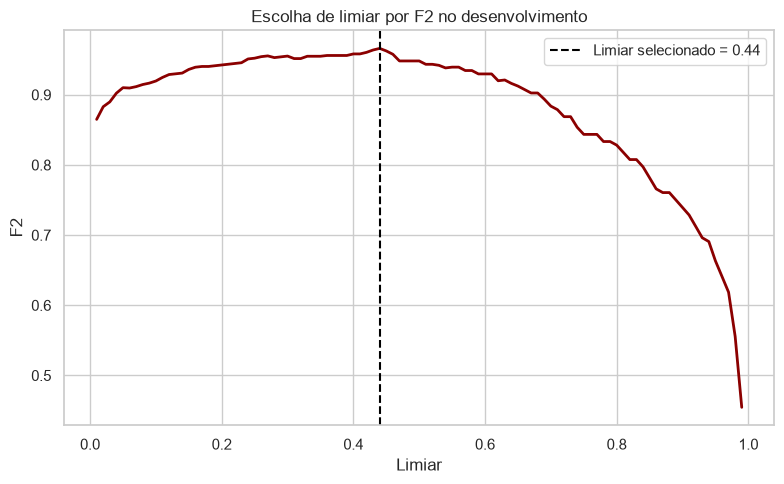

In [ ]:
# ------------------------------------------------------------
# 9. Escolha de limiar dentro do desenvolvimento
# ------------------------------------------------------------
# Para escolher o limiar sem usar o teste, vamos obter probabilidades
# por validação cruzada manualmente com os melhores hiperparâmetros.
#
# A ideia é: em cada fold, o modelo é reajustado somente no treino
# daquela fold e prevê a fold de validação.
from sklearn.base import clone

probabilidades_oof = np.zeros(len(X_desenvolvimento))

for indices_treino, indices_validacao in cv_interna.split(
    X_desenvolvimento,
    y_desenvolvimento
):
    X_fold_treino = X_desenvolvimento.iloc[indices_treino]
    y_fold_treino = y_desenvolvimento.iloc[indices_treino]

    X_fold_validacao = X_desenvolvimento.iloc[indices_validacao]

    modelo_fold = clone(melhor_modelo)
    modelo_fold.fit(X_fold_treino, y_fold_treino)

    probabilidades_oof[indices_validacao] = (
        modelo_fold.predict_proba(X_fold_validacao)[:, 1]
    )

# Para o exemplo, adotamos F2: maior peso para sensibilidade.
# Em doença grave, falsos negativos tendem a ser particularmente custosos.
beta = 2

limiares = np.linspace(0.01, 0.99, 99)
valores_f2 = []

for limiar in limiares:
    classe_oof = (probabilidades_oof >= limiar).astype(int)

    valor_f2 = fbeta_score(
        y_desenvolvimento,
        classe_oof,
        beta=beta,
        zero_division=0
    )

    valores_f2.append(valor_f2)

indice_melhor_limiar = np.argmax(valores_f2)
limiar_otimo = limiares[indice_melhor_limiar]



In [ ]:
print("\n" + "=" * 70)
print("ESCOLHA DO LIMIAR NO CONJUNTO DE DESENVOLVIMENTO")
print("=" * 70)
print(f"Critério: maximizar F{beta}")
print(f"Limiar escolhido: {limiar_otimo:.2f}")
print(f"F{beta} out-of-fold: {valores_f2[indice_melhor_limiar]:.4f}")



In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(limiares, valores_f2, color="darkred", linewidth=2)
plt.axvline(
    limiar_otimo,
    color="black",
    linestyle="--",
    label=f"Limiar selecionado = {limiar_otimo:.2f}"
)
plt.xlabel("Limiar")
plt.ylabel(f"F{beta}")
plt.title(f"Escolha de limiar por F{beta} no desenvolvimento")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
# ------------------------------------------------------------
# 10. Avaliação única no teste final
# ------------------------------------------------------------
# O teste é usado agora pela primeira vez.
prob_teste = melhor_modelo.predict_proba(X_teste)[:, 1]
classe_teste = (prob_teste >= limiar_otimo).astype(int)

# Métricas de ordenação e probabilidade
pr_auc_teste = average_precision_score(y_teste, prob_teste)
roc_auc_teste = roc_auc_score(y_teste, prob_teste)
brier_teste = brier_score_loss(y_teste, prob_teste)

# Métricas baseadas no limiar operacional escolhido
sensibilidade = recall_score(y_teste, classe_teste, zero_division=0)
precisao = precision_score(y_teste, classe_teste, zero_division=0)
f1 = f1_score(y_teste, classe_teste, zero_division=0)
f2 = fbeta_score(y_teste, classe_teste, beta=2, zero_division=0)
acuracia_balanceada = balanced_accuracy_score(y_teste, classe_teste)

tn, fp, fn, tp = confusion_matrix(y_teste, classe_teste).ravel()
especificidade = tn / (tn + fp)

resultado_teste = pd.DataFrame({
    "Métrica": [
        "PR-AUC / Average Precision",
        "ROC-AUC",
        "Brier score",
        "Sensibilidade / Recall",
        "Especificidade",
        "Precisão / PPV",
        "F1",
        "F2",
        "Balanced accuracy"
    ],
    "Teste final": [
        pr_auc_teste,
        roc_auc_teste,
        brier_teste,
        sensibilidade,
        especificidade,
        precisao,
        f1,
        f2,
        acuracia_balanceada
    ]
})




AVALIAÇÃO FINAL EM DADOS NÃO VISTOS
Modelo selecionado: Bagging
Limiar operacional: 0.44

                   Métrica  Teste final
PR-AUC / Average Precision       0.9957
                   ROC-AUC       0.9975
               Brier score       0.0270
    Sensibilidade / Recall       0.9762
            Especificidade       0.9444
            Precisão / PPV       0.9111
                        F1       0.9425
                        F2       0.9624
         Balanced accuracy       0.9603

Matriz de confusão:
VN = 68
FP = 4
FN = 1
VP = 41

Relatório de classificação:
              precision    recall  f1-score   support

     Benigno     0.9855    0.9444    0.9645        72
     Maligno     0.9111    0.9762    0.9425        42

    accuracy                         0.9561       114
   macro avg     0.9483    0.9603    0.9535       114
weighted avg     0.9581    0.9561    0.9564       114



In [ ]:
print("\n" + "=" * 70)
print("AVALIAÇÃO FINAL EM DADOS NÃO VISTOS")
print("=" * 70)
print(f"Modelo selecionado: {melhor_nome}")
print(f"Limiar operacional: {limiar_otimo:.2f}\n")
print(resultado_teste.round(4).to_string(index=False))



In [ ]:
print("\nMatriz de confusão:")
print(f"VN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"VP = {tp}")



In [ ]:
print("\nRelatório de classificação:")
print(
    classification_report(
        y_teste,
        classe_teste,
        target_names=["Benigno", "Maligno"],
        digits=4,
        zero_division=0
    )
)



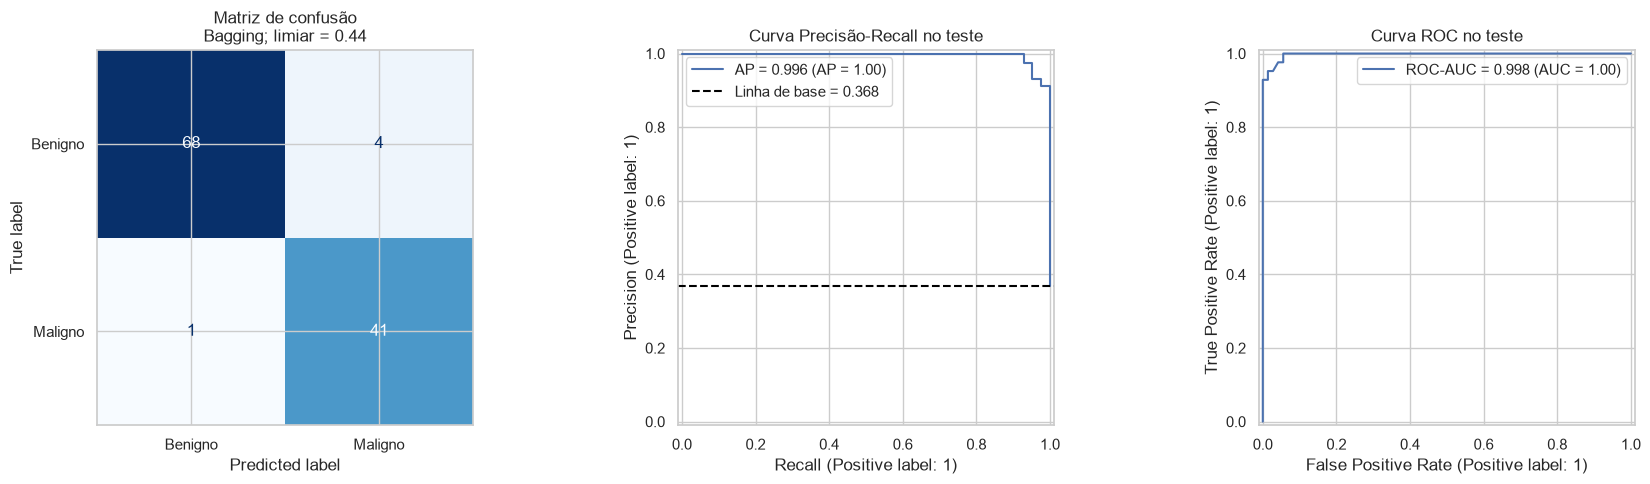

In [ ]:
# ------------------------------------------------------------
# 11. Gráficos de avaliação no teste
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_teste, classe_teste),
    display_labels=["Benigno", "Maligno"]
).plot(cmap="binary", values_format="d", colorbar=False, ax=axes[0])

axes[0].set_title(
    f"Matriz de confusão\n{melhor_nome}; limiar = {limiar_otimo:.2f}"
)

PrecisionRecallDisplay.from_predictions(
    y_teste,
    prob_teste,
    ax=axes[1],
    name=f"AP = {pr_auc_teste:.3f}"
)

axes[1].axhline(
    y=y_teste.mean(),
    color="black",
    linestyle="--",
    label=f"Linha de base = {y_teste.mean():.3f}"
)

axes[1].set_title("Curva Precisão-Recall no teste")
axes[1].legend()

RocCurveDisplay.from_predictions(
    y_teste,
    prob_teste,
    ax=axes[2],
    name=f"ROC-AUC = {roc_auc_teste:.3f}"
)

axes[2].set_title("Curva ROC no teste")
axes[2].legend()

plt.tight_layout()
plt.show()



In [ ]:
# ------------------------------------------------------------
# 12. Visualização se a árvore vencer
# ------------------------------------------------------------
if melhor_nome == "Árvore de decisão":

    arvore_final = melhor_modelo.named_steps["modelo"]

    plt.figure(figsize=(12, 12))

    plot_tree(
        arvore_final,
        feature_names=X.columns,
        class_names=["Benigno", "Maligno"],
        filled=True,
        rounded=True,
        proportion=True,
        precision=2,
        fontsize=8
    )

    plt.title("Árvore de decisão selecionada por GridSearchCV")
    plt.show()